# Stitching Opal 
### Inspired by Nina's Groovy Script


In [1]:
from aicsimageio import AICSImage

import os
import numpy as np
#from pyclesperanto_prototype import imshow
#import pyclesperanto_prototype as cle
import dask.array as da

import numpy as np
from matplotlib import pyplot as plt
import re

from tifffile import TiffWriter
import tifffile
from skimage.transform import resize

from xml.etree import ElementTree as ET


#### Get All Images

In [7]:
#histology_share = '/stornext/ImageData/histology-images/polaris/lee.b/inform images/CHP004 panel 2/'
#data_directory = '22.86 JN/SCLCC - 1/'
#microscopy = '/stornext/Img/data/microscopy_data/lab_scott/shieldartin.k/OPAL/Processed Images/Asha_SOL2pilot/'
#microscopy_data = '/stornext/Img/data/microscopy_data/lab_asselin-labat/yao.e/Opal Work/QuPath Projects/KP-319 Short-Term Combo Study 2 (Opal)/Unstitched Images/'
#data_directory = ''
#fpath = os.path.join(histology_share,data_directory)

#fpath = '/vast/scratch/users/whitehead/kristy_opal/SOL2_0007_14MP_Scan1/'
#fpath = microscopy_data
fpath = '/vast/scratch/users/whitehead/stitch_source/image2/'
outDir = '/vast/scratch/users/whitehead/stitches/'



all_flist = os.listdir(fpath)
print(len(all_flist))


flist = [f for f in all_flist if 'W' in f]
print(len(flist))

459
459


#### Get just the first slide

In [8]:
#reg = r"([0-9]+)_Scan1_\[([0-9]+),([0-9]+)\]_component_data\.tif"
#reg0 = r"([0])_Scan1_\[([0-9]+),([0-9]+)\]_component_data\.tif"
#reg0 = r"(.*)_(Scan[0-9]+)_\[([0-9]+),([0-9]+)\]_component_data\.tif"
reg0 = r"(.*)_\[([0-9]+),([0-9]+)\]_component_data\.tif"
thisImage = [f for f in flist if re.match(reg0,f)]
print(len(thisImage))

#group 2 is X group 3 is Y

459


In [9]:
m = re.match(reg0,flist[5])
print(m.group(1)) #image label
print(m.group(2)) #scan number
print(m.group(3))
#outFileName = "%s_stitch" % (m.group(1))
#print(outFileName)

label = m.group(1)
print(label)

WIHA 2nd slide
10430
53159
WIHA 2nd slide


#### Get all image region locations

In [10]:
temp = np.zeros(500)
#pixelScale = 0.49641833810888253
pixelScale = 0.4962808

cpt = 0
imBoxes = []

for idx,f in enumerate(thisImage):
    #Find X Values list
    m = re.match(reg0,f)
    if m:
        xVal = int(int(m.group(2))/pixelScale)
        yVal = int(int(m.group(3))/pixelScale)
    
    #Parse region
    img_path = os.path.join(fpath,f)
    img = AICSImage(img_path)   
    z,c,t,x,y = img.shape
    imBoxes.append([xVal,yVal,xVal+x,yVal+y])

    if (idx==0):
        #If first image, open using tiffffile to read channel names
        imgData = tifffile.TiffFile(img_path)
        imgData_s0 = imgData.series[0]
        names = [(ET.fromstring(page.description).find('Name').text) for page in imgData_s0]
        colors = [(ET.fromstring(page.description).find('Color').text) for page in imgData_s0]
    
        
        

    

    

In [11]:
print(colors)
new_colors = []
for cl in colors:
    cl = str.split(cl,',')
    a = 1
    r = int(cl[0])
    g = int(cl[1])
    b = int(cl[2])
    RGBint = int.from_bytes([r,g,b,a],byteorder="big", signed=True)   
    new_colors.append(RGBint)
    
    
print(new_colors)
    


['0,255,0', '255,0,0', '255,0,255', '255,128,0', '255,255,0', '0,45,255', '0,0,0']
[16711681, -16777215, -16711935, -8388607, -65535, 3014401, 1]


#### Get Final Image Size

In [12]:
xvals = [x[0] for x in imBoxes]
yvals = [x[1] for x in imBoxes]
x_end_vals = [x[2] for x in imBoxes]
y_end_vals = [x[3] for x in imBoxes]


im_xmin = min(xvals)
im_ymin = min(yvals)
im_xmax = max(x_end_vals)
im_ymax = max(y_end_vals)

final_dimensions = (im_xmax - im_xmin, im_ymax - im_ymin)
print(final_dimensions)


(37326, 73820)


## FIND ROIs?

##  initialise Image 

In [8]:
# Downscale and find Rois first?


In [13]:
scale_by = 8
small_version = da.zeros((int(final_dimensions[0]/scale_by),int(final_dimensions[1]/scale_by)))
print(small_version.shape)
small_version


(4665, 9227)


dask.array<zeros_like, shape=(4665, 9227), dtype=float64, chunksize=(4096, 4096), chunktype=numpy.ndarray>

In [14]:
thisImage = sorted(thisImage)

for idx,f in enumerate(thisImage):
    impath = os.path.join(fpath,f)
    
    m = re.match(reg0,f)
    if m:
        xVal = int(int(m.group(2))/pixelScale)
        yVal = int(int(m.group(3))/pixelScale)

    img_path = os.path.join(fpath,f)
    img = AICSImage(img_path)
    z,c,t,h,w = img.shape
    xStart = xVal - im_xmin 
    yStart = yVal - im_ymin
    xEnd = xStart + w
    yEnd = yStart + h 
    
    xStart = int(xStart / scale_by)
    yStart = int(yStart / scale_by)
    yEnd = int(yEnd / scale_by)
    xEnd = int(xEnd / scale_by)
    
    print(f)
    print(idx,xStart,yStart,xEnd,yEnd)    
    
    try: 
        small_version[xStart:xEnd,yStart:yEnd] = 1
        
    except:
        print("SHAPE MISMATCH")
        print("ROI:")
        print(small_version[xStart:xEnd,yStart:yEnd].shape);
        print("im_data:")
        print(im_data.shape)
    
        roiShape = small_version[xStart:xEnd,yStart:yEnd].shape
        
        small_version[xStart:xEnd,yStart:yEnd] = 1#im_data[:,:,:,0:roiShape[3],0:roiShape[4]]
        
        
    #   print(idx,"oops")
    #   casss
    
    
print("DONE")

WIHA 2nd slide_[10430,49055]_component_data.tif
0 1367 3451 1600 3626
WIHA 2nd slide_[10430,49739]_component_data.tif
1 1367 3624 1600 3799
WIHA 2nd slide_[10430,50423]_component_data.tif
2 1367 3796 1600 3971
WIHA 2nd slide_[10430,51107]_component_data.tif
3 1367 3968 1600 4143
WIHA 2nd slide_[10430,52475]_component_data.tif
4 1367 4313 1600 4488
WIHA 2nd slide_[10430,53159]_component_data.tif
5 1367 4485 1600 4660
WIHA 2nd slide_[10430,53843]_component_data.tif
6 1367 4657 1600 4832
WIHA 2nd slide_[10430,54527]_component_data.tif
7 1367 4830 1600 5005
WIHA 2nd slide_[10471,58065]_component_data.tif
8 1377 5721 1610 5896
WIHA 2nd slide_[10471,58749]_component_data.tif
9 1377 5893 1610 6068
WIHA 2nd slide_[10471,59433]_component_data.tif
10 1377 6065 1610 6240
WIHA 2nd slide_[10471,60117]_component_data.tif
11 1377 6238 1610 6413
WIHA 2nd slide_[10471,60801]_component_data.tif
12 1377 6410 1610 6585
WIHA 2nd slide_[10471,61485]_component_data.tif
13 1377 6582 1610 6757
WIHA 2nd slide_[

In [15]:
from skimage.measure import label, regionprops
from skimage.morphology import closing,square

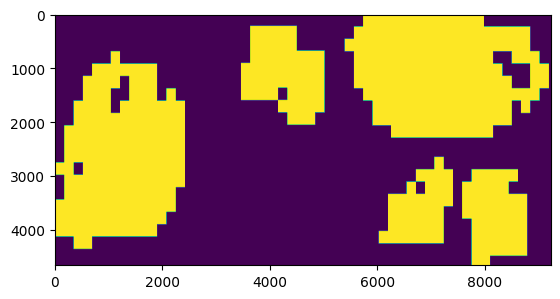

In [16]:
small_version = small_version.compute()
plt.imshow(small_version)

In [17]:
clsed = closing(small_version,square(1))

/tmp/ipykernel_1925499/61845818.py:1: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  clsed = closing(small_version,square(1))


In [18]:
lbl = label(clsed)

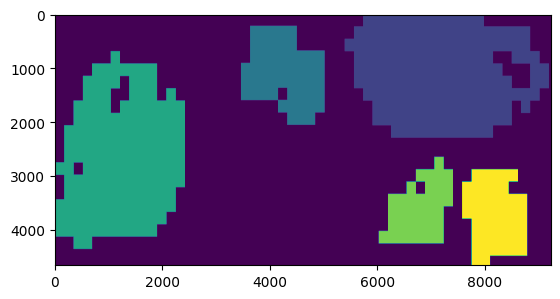

In [19]:
plt.imshow(lbl)

In [23]:
regions = regionprops(lbl)

In [24]:
for r in regions:
    print(r.bbox)

(0, 5376, 2299, 9169)
(219, 3451, 2059, 5005)
(690, 0, 4366, 2414)
(2654, 6009, 4264, 7390)
(2883, 7559, 4665, 8768)


In [25]:
roi1 = regions[0].bbox
roi1

(0, 5376, 2299, 9169)

In [26]:
y0,x0,y1,x1 = roi1
full_height = y1-y0
full_width = x1-x0

x0 = x0 * scale_by
y0 = y0 * scale_by
y1 = y1 * scale_by
x1 = x1 * scale_by

print(x0,y0,x1,y1)
full_width = full_width * scale_by
full_height = full_height * scale_by

print(full_height,full_width)

43008 0 73352 18392
18392 30344


In [27]:
full_height = final_dimensions[0]
full_width = final_dimensions[1]

In [28]:
stitched_image = da.zeros((1,int(c),1,full_height,full_width))
stithced_image = stitched_image.rechunk((1,int(c),1,
                                         int(full_height/10),
                                         int(full_width/10)))
print(stitched_image.shape)

stithced_image = stitched_image.rechunk(block_size_limit=1e7)

#stitched_image = stitched_image.swapaxes(3,4)

(1, 7, 1, 37326, 73820)


In [29]:
stitched_image


dask.array<zeros_like, shape=(1, 7, 1, 37326, 73820), dtype=float64, chunksize=(1, 7, 1, 1548, 1548), chunktype=numpy.ndarray>

# The Meat 
## Put the images tiles where they go

In [30]:
%%time
thisImage = sorted(thisImage)
for idx,f in enumerate(thisImage):
    impath = os.path.join(fpath,f)
    
    m = re.match(reg0,f)
    if m:
        xVal = int(int(m.group(2))/pixelScale)
        yVal = int(int(m.group(3))/pixelScale)
            
    #Parse region
    img_path = os.path.join(fpath,f)
    img = AICSImage(img_path)
    z,c,t,h,w = img.shape
    im_data = img.get_image_data()    
    im_data = np.swapaxes(im_data,3,4)
        
    xStart = xVal - im_xmin 
    yStart = yVal - im_ymin
    xEnd = xStart + w
    yEnd = yStart + h 
    
    print(f)
    print(idx,xStart,yStart,xEnd,yEnd) 
    
    xc, yc = xStart + w/2, yStart + w/2
    

    try: 
        stitched_image[:,:,:,xStart:xEnd,yStart:yEnd] = im_data

    except ValueError:
        pass
    
    except :
        print("SHAPE MISMATCH")
        print("ROI:")
        print(stitched_image[:,:,:,xStart:xEnd,yStart:yEnd].shape);
        print("im_data:")
        print(im_data.shape)

        roiShape = stitched_image[:,:,:,xStart:xEnd,yStart:yEnd].shape

        stitched_image[:,:,:,xStart:xEnd,yStart:yEnd] = im_data[:,:,:,0:roiShape[3],0:roiShape[4]]


    #   print(idx,"oops")
    #   casss
    
    
print("DONE")

full_image = stitched_image


WIHA 2nd slide_[10430,49055]_component_data.tif
0 10938 27614 12802 29014
WIHA 2nd slide_[10430,49739]_component_data.tif
1 10938 28992 12802 30392
WIHA 2nd slide_[10430,50423]_component_data.tif
2 10938 30370 12802 31770
WIHA 2nd slide_[10430,51107]_component_data.tif
3 10938 31749 12802 33149
WIHA 2nd slide_[10430,52475]_component_data.tif
4 10938 34505 12802 35905
WIHA 2nd slide_[10430,53159]_component_data.tif
5 10938 35883 12802 37283
WIHA 2nd slide_[10430,53843]_component_data.tif
6 10938 37262 12802 38662
WIHA 2nd slide_[10430,54527]_component_data.tif
7 10938 38640 12802 40040
WIHA 2nd slide_[10471,58065]_component_data.tif
8 11020 45769 12884 47169
WIHA 2nd slide_[10471,58749]_component_data.tif
9 11020 47147 12884 48547
WIHA 2nd slide_[10471,59433]_component_data.tif
10 11020 48525 12884 49925
WIHA 2nd slide_[10471,60117]_component_data.tif
11 11020 49904 12884 51304
WIHA 2nd slide_[10471,60801]_component_data.tif
12 11020 51282 12884 52682
WIHA 2nd slide_[10471,61485]_compon

In [24]:
print(im_data.shape)

(1, 7, 1, 1864, 1400)


In [31]:
y0,x0,y1,x1 = roi1
full_height = y1-y0
full_width = x1-x0

x0 = x0 * scale_by
y0 = y0 * scale_by
y1 = y1 * scale_by
x1 = x1 * scale_by

print(x0,y0,x1,y1)

43008 0 73352 18392


In [32]:
#stitched_image = full_image[:,:,:,0:18750,3070:10100]
stitched_image = full_image[:,:,:,y0:y1,x0:x1]


In [33]:
stitched_image.shape

(1, 7, 1, 18392, 30344)

### Pre-compute the image pyramid

In [30]:
%%time 
im_to_write = stitched_image
subFig1 = resize(im_to_write,(im_to_write.shape[0],
                                im_to_write.shape[1],
                                im_to_write.shape[2],
                                im_to_write.shape[3]/4,
                                im_to_write.shape[4]/4))

subFig2 = resize(subFig1,(subFig1.shape[0],
                                subFig1.shape[1],
                                subFig1.shape[2],
                                subFig1.shape[3]/4,
                                subFig1.shape[4]/4))
# Save OME.TIFF 

CPU times: user 6min, sys: 1min 48s, total: 7min 48s
Wall time: 5min 57s


In [34]:
print(outDir)
label = m.group(1)
print(label)

/vast/scratch/users/whitehead/stitches/
WIHA 2nd slide


In [35]:

for idx,r in enumerate(regions):

    y0,x0,y1,x1 = r.bbox
   
    x0 = x0 * scale_by
    y0 = y0 * scale_by
    y1 = y1 * scale_by
    x1 = x1 * scale_by
    print(x0,x1,y0,y1)
    stitched_image = full_image[:,:,:,y0:y1,x0:x1]
 

    im_to_write = stitched_image
    subFig1 = resize(im_to_write,(im_to_write.shape[0],
                                    im_to_write.shape[1],
                                    im_to_write.shape[2],
                                    im_to_write.shape[3]/4,
                                    im_to_write.shape[4]/4))

    subFig2 = resize(subFig1,(subFig1.shape[0],
                                    subFig1.shape[1],
                                    subFig1.shape[2],
                                    subFig1.shape[3]/4,
                                    subFig1.shape[4]/4))


    
    outFileName =  "%s_stitch_roi_%i.ome.tif" % (label,idx)
    outPath = os.path.join(outDir,outFileName)

    
    with TiffWriter(outPath, bigtiff=True) as tif:
        
        options = dict(tile=(512, 512),compression='zlib',
                       metadata={'axes': 'TCZYX',
                                 'PhysicalSizeX':pixelScale,
                                 'PhysicalSizeY':pixelScale,
                                 'Channel':{'Name':names,'Color':new_colors}                          
                                }                               
                      )

        print('writing file %s' % outPath)
        tif.write(im_to_write, subifds=2, **options)
        # save pyramid levels to the two subifds
        print("Pyramid resolution 1")
        tif.write(subFig1, subfiletype=1, **options)
        print("Pyramid resolution 2")
        tif.write(subFig2, subfiletype=1, **options)


43008 73352 0 18392
writing file /vast/scratch/users/whitehead/stitches/WIHA 2nd slide_stitch_roi_0.ome.tif
Pyramid resolution 1
Pyramid resolution 2
27608 40040 1752 16472
writing file /vast/scratch/users/whitehead/stitches/WIHA 2nd slide_stitch_roi_1.ome.tif
Pyramid resolution 1
Pyramid resolution 2
0 19312 5520 34928
writing file /vast/scratch/users/whitehead/stitches/WIHA 2nd slide_stitch_roi_2.ome.tif
Pyramid resolution 1
Pyramid resolution 2
48072 59120 21232 34112
writing file /vast/scratch/users/whitehead/stitches/WIHA 2nd slide_stitch_roi_3.ome.tif
Pyramid resolution 1
Pyramid resolution 2
60472 70144 23064 37320
writing file /vast/scratch/users/whitehead/stitches/WIHA 2nd slide_stitch_roi_4.ome.tif
Pyramid resolution 1
Pyramid resolution 2


In [ ]:
print(outPath)